# # Customer Data EDA Project


First 5 Rows:
   Customer_ID  Age  Gender  Annual_Income  Spending_Score
0            1   22    Male          25000              35
1            2   25  Female          35000              65
2            3   28  Female          42000              72
3            4   35    Male          55000              40
4            5   40  Female          70000              80

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Customer_ID     20 non-null     int64 
 1   Age             20 non-null     int64 
 2   Gender          20 non-null     object
 3   Annual_Income   20 non-null     int64 
 4   Spending_Score  20 non-null     int64 
dtypes: int64(4), object(1)
memory usage: 932.0+ bytes
None

Dataset Shape:
Rows: 20
Columns: 5

Column Names:
['Customer_ID', 'Age', 'Gender', 'Annual_Income', 'Spending_Score']

Missing Values:
Cust

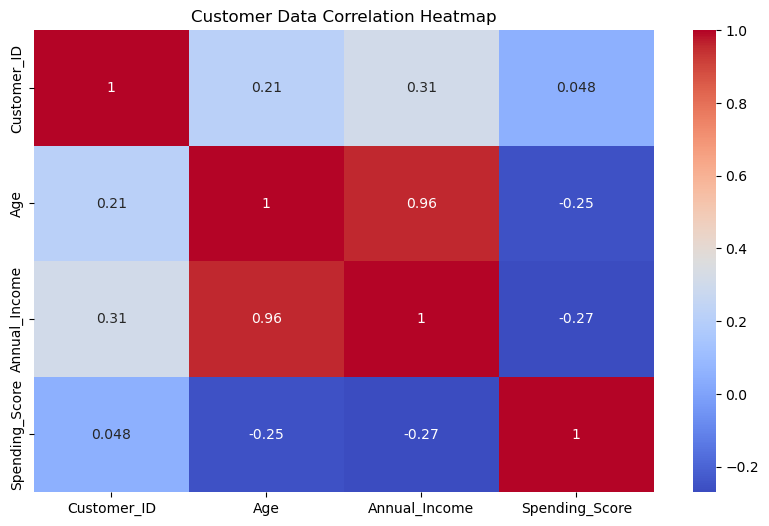

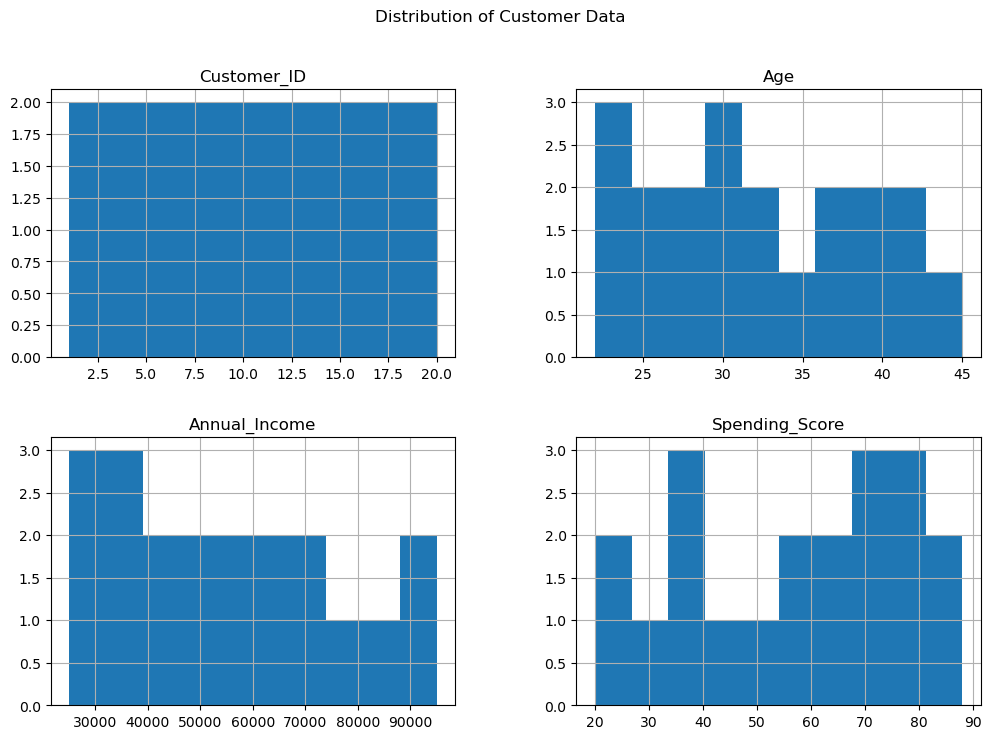

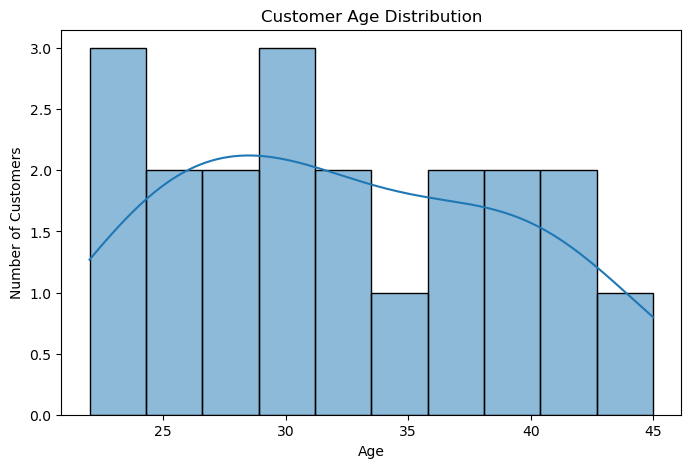

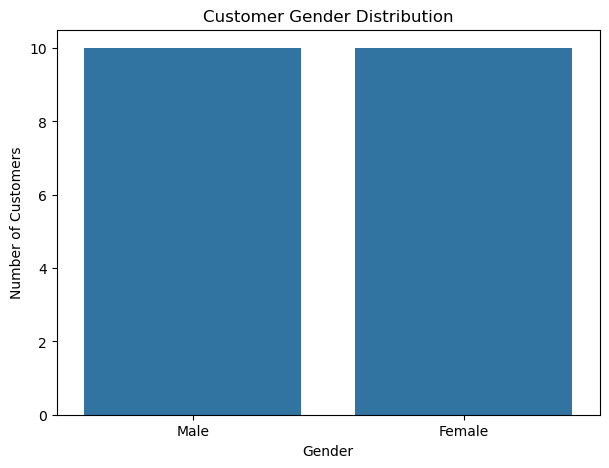


Income Segments:
Income_Segment
Medium       10
High          7
Low           3
Very High     0
Name: count, dtype: int64


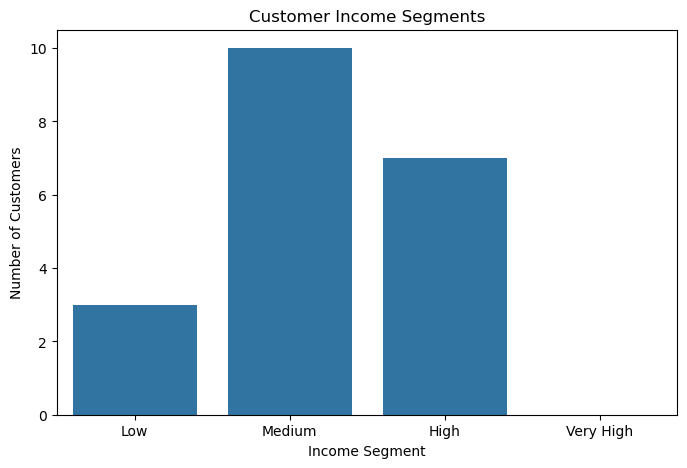

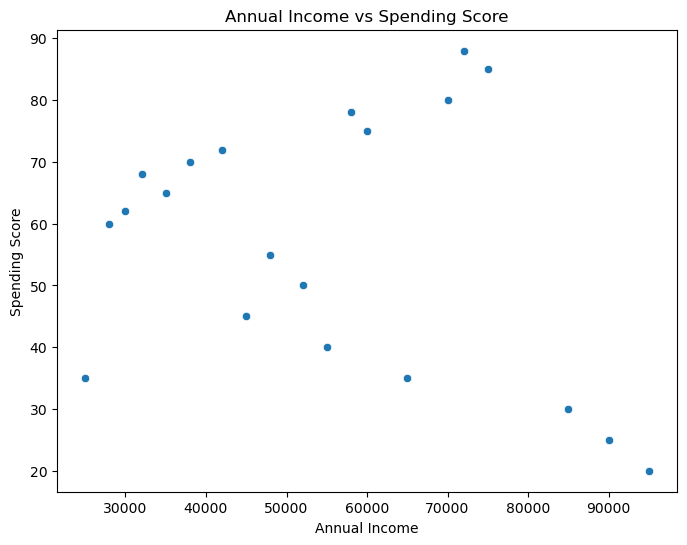


Spending Segments:
Spending_Segment
Medium Spending    8
Low Spending       6
High Spending      6
Name: count, dtype: int64

Average Income by Gender:
Gender
Female    46800.0
Male      63200.0
Name: Annual_Income, dtype: float64

Average Spending Score:
56.9

Final Dataset:
   Customer_ID  Age  Gender  Annual_Income  Spending_Score Income_Segment  \
0            1   22    Male          25000              35            Low   
1            2   25  Female          35000              65         Medium   
2            3   28  Female          42000              72         Medium   
3            4   35    Male          55000              40         Medium   
4            5   40  Female          70000              80           High   

  Spending_Segment  
0     Low Spending  
1  Medium Spending  
2    High Spending  
3     Low Spending  
4    High Spending  

Cleaned customer dataset saved successfully!


In [3]:
# Customer Data EDA Project
# Technologies: Python, Pandas, NumPy, Matplotlib, Seaborn

# 1. Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# 2. Load Dataset
# Change the file name if your CSV has a different name
df = pd.read_csv("customer_data.csv")


# 3. Display First 5 Rows
print("First 5 Rows:")
print(df.head())


# 4. Dataset Information
print("\nDataset Information:")
print(df.info())


# 5. Check Shape
print("\nDataset Shape:")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])


# 6. Check Column Names
print("\nColumn Names:")
print(df.columns.tolist())


# 7. Check Missing Values
print("\nMissing Values:")
print(df.isnull().sum())


# 8. Check Duplicate Values
print("\nDuplicate Rows:")
print(df.duplicated().sum())


# 9. Statistical Summary
print("\nStatistical Summary:")
print(df.describe())


# 10. Handle Missing Values
# Fill numerical missing values with median
numeric_columns = df.select_dtypes(include=np.number).columns

for column in numeric_columns:
    df[column] = df[column].fillna(df[column].median())


# Fill categorical missing values with mode
categorical_columns = df.select_dtypes(include="object").columns

for column in categorical_columns:
    if df[column].isnull().sum() > 0:
        df[column] = df[column].fillna(df[column].mode()[0])


# 11. Remove Duplicate Rows
df = df.drop_duplicates()


# 12. Check Missing Values Again
print("\nMissing Values After Cleaning:")
print(df.isnull().sum())


# 13. Numerical Columns
print("\nNumerical Columns:")
print(df.select_dtypes(include=np.number).columns.tolist())


# 14. Categorical Columns
print("\nCategorical Columns:")
print(df.select_dtypes(include="object").columns.tolist())


# 15. Correlation Analysis
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(10, 6))
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm")
plt.title("Customer Data Correlation Heatmap")
plt.show()


# 16. Distribution of Numerical Data
numeric_df.hist(figsize=(12, 8))
plt.suptitle("Distribution of Customer Data")
plt.show()


# 17. Customer Age Distribution
if "Age" in df.columns:
    plt.figure(figsize=(8, 5))
    sns.histplot(df["Age"], bins=10, kde=True)
    plt.title("Customer Age Distribution")
    plt.xlabel("Age")
    plt.ylabel("Number of Customers")
    plt.show()


# 18. Gender Distribution
if "Gender" in df.columns:
    plt.figure(figsize=(7, 5))
    sns.countplot(data=df, x="Gender")
    plt.title("Customer Gender Distribution")
    plt.xlabel("Gender")
    plt.ylabel("Number of Customers")
    plt.show()


# 19. Customer Segmentation by Income
if "Annual_Income" in df.columns:
    df["Income_Segment"] = pd.cut(
        df["Annual_Income"],
        bins=[0, 30000, 60000, 100000, np.inf],
        labels=["Low", "Medium", "High", "Very High"]
    )

    print("\nIncome Segments:")
    print(df["Income_Segment"].value_counts())

    plt.figure(figsize=(8, 5))
    sns.countplot(data=df, x="Income_Segment")
    plt.title("Customer Income Segments")
    plt.xlabel("Income Segment")
    plt.ylabel("Number of Customers")
    plt.show()


# 20. Spending Analysis
if "Annual_Income" in df.columns and "Spending_Score" in df.columns:
    plt.figure(figsize=(8, 6))
    sns.scatterplot(
        data=df,
        x="Annual_Income",
        y="Spending_Score"
    )
    plt.title("Annual Income vs Spending Score")
    plt.xlabel("Annual Income")
    plt.ylabel("Spending Score")
    plt.show()


# 21. Customer Segments Based on Spending Score
if "Spending_Score" in df.columns:
    df["Spending_Segment"] = pd.cut(
        df["Spending_Score"],
        bins=[0, 40, 70, 100],
        labels=["Low Spending", "Medium Spending", "High Spending"]
    )

    print("\nSpending Segments:")
    print(df["Spending_Segment"].value_counts())


# 22. Group Analysis
if "Gender" in df.columns and "Annual_Income" in df.columns:
    print("\nAverage Income by Gender:")
    print(df.groupby("Gender", observed=True)["Annual_Income"].mean())


# 23. Average Spending Score
if "Spending_Score" in df.columns:
    print("\nAverage Spending Score:")
    print(df["Spending_Score"].mean())


# 24. Final Dataset
print("\nFinal Dataset:")
print(df.head())


# 25. Save Cleaned Dataset
df.to_csv("cleaned_customer_data.csv", index=False)

print("\nCleaned customer dataset saved successfully!")